`[1]`

# Seleção de variáveis e avaliação nos pontos — fosfato na região completa (grid 5 × 5)

Escolhe as variáveis e o fundo de treino do RF e do GTB de fosfato na região toda,
só com o mosaico ASTER (14 bandas, 17 índices, `phosphorite_rbd`, 4 GLCM). Mesmo
desenho do `area_reduzida/selecao_variaveis_AR.ipynb`, com duas diferenças:
- **folds = células da grid 5 × 5** (uma célula de fora por vez, presença e fundo
  juntos), as mesmas células do export por célula;
- sem geofísica nem geologia, e sem a conferência com P₂O₅ (as amostras de rocha só
  existem na área reduzida). No lugar, a **validação R2**: treina com os pontos da
  bacia (`papel = treino`) e testa nos de fora (`papel = validacao`).

| Peça | Papel |
|---|---|
| `models_ML_fosfato.py` (opção 1) | amostras no GEE → `maxent_amostras_<mosaico>_bandas_indices` |
| `baixar_amostras_maxent.py` | CSV em `src/Dados/maxent/` |
| este notebook | variáveis → `models/variaveis_RC_<sufixo>.json` ([21]) e fundo → `models/cluster_fundo_RC_<sufixo>.json` ([10e]) |
| `exportar_favorabilidade_ml.py` | mapas RF/GTB por célula no GEE com o conjunto escolhido |

**Seções**
1. Dados e exploração
2. Redundância (Spearman no fundo)
3. Validação espacial por célula da grid; fundo de treino por cluster
4. Ablação por grupo de variáveis (o SWIR estimado ajuda ou atrapalha?)
5. Ranking estável (SHAP fora da amostra em reamostragens)
6. Avaliação nos pontos: p de cada ocorrência fora da amostra e validação R2
7. Variáveis salvas para o export

In [1]:
# [1I]
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=UserWarning)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

In [6]:
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Dados').exists())   # src/
PASTA = RAIZ / 'Dados' / 'maxent'
MODELS = RAIZ / 'modeling' / 'models'

# mosaico das amostras; o sufixo vai nos nomes dos arquivos (o mesmo SUFIXOS do exportar_favorabilidade_ml.py)
MOSAICO = 'aster-mosaico-final_sazonal_hm_razao'
SUFIXOS = {'aster-mosaico-final': 'v1', 'aster-mosaico-final_sazonal_hm_razao': 'shm',
           'ASTER_mosaico_unico_final': 'unico'}
ID_RC = SUFIXOS[MOSAICO]
ARQ = PASTA / f'maxent_amostras_{MOSAICO}_bandas_indices.csv'
FIGS = MODELS / 'figuras_selecao_RC'
FIGS.mkdir(parents=True, exist_ok=True)

# ── parâmetros da análise ───────────────────────────────────────────────────
ALVO          = 'fosfato'
PAPEIS        = None      # None = todos os pontos (como o export com PAPEIS = None); ['treino'] = só a bacia
R_MAX         = 0.85      # |Spearman| acima disso = redundante
N_REP         = 20        # reamostragens do ranking estável
FRAC_REP      = 0.8       # fração das ocorrências em cada reamostragem
TOP_K         = 15        # "no topo" = entre as TOP_K mais importantes
FREQ_MIN      = 0.7       # entra quem fica no topo em ≥ 70% das repetições
N_MIN_SEL     = 15        # SELECAO com pelo menos N_MIN_SEL variáveis (completa pela freq_topo e |SHAP|)
SHAP_N        = 300       # amostras explicadas por célula de teste (metade presença, metade fundo)
SHAP_MODELOS  = ['GTB', 'RF']
N_BOOT        = 1000      # bootstrap das ocorrências (intervalo da AUC por ponto)
FUNDO_MODO    = 'cluster' # fundo do TREINO: 'aleatorio' (todo) ou 'cluster' (só clusters distantes, [10a])
K_FUNDO       = 10        # k-means: número de clusters do fundo
# regra do fundo de treino por cluster:
#   'n_distantes' = os N_CLUSTERS_FUNDO clusters mais distantes do cluster fosfato (sem ocorrência)
#   'raio'        = todos os clusters sem ocorrência além do raio do fosfato (regra do código do AR)
REGRA_FUNDO   = 'n_distantes'
N_CLUSTERS_FUNDO = 2
FRAC_MIN_FUNDO = 0.2      # se os escolhidos somarem menos que isso do fundo, entram os próximos mais distantes
VARS_CLUSTER  = None      # None = as variáveis sem redundância do conjunto 'todas' ([8])
FATOR_FUNDO   = 3         # o mesmo do exportar_favorabilidade_ml.py
SEED          = 42
rng = np.random.default_rng(SEED)
DPI_FIG = 350

# 21 do SHAP do v1 (avaliar_maxent [34]) = conjunto 'fixas' do export; também a ordem de
# preferência para representar um grupo redundante
FEATURES_V1 = ['quartz_14_12', 'B10', 'ferric_iron_2_1', 'glcm_contrast', 'B09', 'sultan_g',
               'phosphorite_rbd', 'gossan_4_2', 'sultan_r', 'ferric_ox_4_3', 'SAVI', 'B01', 'B3N',
               'carbonate_13_14', 'kaolinite_7_5', 'carbonate_8_6', 'glcm_hom', 'dolomite',
               'sericite_illite_smectite', 'muscovite_7_6', 'glcm_ent']
PRIORIDADE = FEATURES_V1

def prioridade(v):
    return PRIORIDADE.index(v) if v in PRIORIDADE else len(PRIORIDADE)

def salvar(fig, celula, nome):
    """Salva a figura em FIGS como c<célula>_<nome>.png a DPI_FIG dpi."""
    arq = FIGS / f'c{celula}_{nome}.png'
    fig.savefig(arq, dpi=DPI_FIG, bbox_inches='tight')
    print(f'figura → {arq.name}')
    return arq

print(RAIZ, ARQ.name, ARQ.exists())

/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src maxent_amostras_aster-mosaico-final_sazonal_hm_razao_bandas_indices.csv True


`[3]`

## 1. Dados e exploração

Presença = os pixels do buffer de 500 m de cada ponto de fosfato (até 20 por ponto,
`models_ML_fosfato.AMOSTRAS_POR_PONTO`); fundo = 10 mil pixels aleatórios, 400 por
célula da grid. A coluna `celula` (1–25, grid com solape) é o fold.

Grupos de variáveis:
- `vnir` B01, B02, B3N; `swir` B04–B09; `tir` B10–B14;
- `indices` (17 + `phosphorite_rbd`); `textura` (GLCM da B3N).

No mosaico sazonal o SWIR é medido no período A (`origem` 1) e **estimado** no B
(`origem` 2–3); os índices com SWIR herdam isso. A ablação (seção 4) mede o efeito.

In [7]:
# [4]
NAO_FEATURE = {'system:index', '.geo', 'CODIGO_OBJ', 'alvo', 'celula', 'classe', 'features_modo',
               'fonte', 'papel', 'origem', 'swir_estimado', 'camada', 'normalizacao', 'data', 'lon', 'lat'}
G = {'vnir': ['B01', 'B02', 'B3N'],
     'swir': ['B04', 'B05', 'B06', 'B07', 'B08', 'B09'],
     'tir':  ['B10', 'B11', 'B12', 'B13', 'B14']}
# índices que usam banda SWIR (B04–B09); os outros ficam no conjunto sem SWIR
INDICES_SWIR = {'ferric_ox_4_3', 'gossan_4_2', 'ferrous_sil_5_4', 'sericite_illite_smectite',
                'alunite_kaolinite_pyrophyllite', 'muscovite_7_6', 'kaolinite_7_5', 'dolomite',
                'carbonate_8_6', 'sultan_r', 'sultan_g', 'sultan_b'}

df = pd.read_csv(ARQ, low_memory=False)
if 'lon' not in df.columns:
    xy = df['.geo'].map(lambda g: json.loads(g)['coordinates'])
    df['lon'], df['lat'] = xy.str[0], xy.str[1]
VARS = sorted(c for c in df.columns if c not in NAO_FEATURE)
G['textura'] = [v for v in VARS if v.startswith('glcm')]
G['indices'] = [v for v in VARS if v not in G['vnir'] + G['swir'] + G['tir'] + G['textura']]
n0 = len(df)
df = df.dropna(subset=VARS).reset_index(drop=True)
print(f'{n0} amostras, {n0 - len(df)} com variável vazia (removidas); {len(VARS)} variáveis',
      {g: len(v) for g, v in G.items()})

PRES = df[(df.classe == 1) & (df.alvo == ALVO)]
if PAPEIS:
    PRES = PRES[PRES.papel.isin(PAPEIS)]
FUNDO = df[df.classe == 0]
OC = PRES.groupby('CODIGO_OBJ').agg(lon=('lon', 'mean'), lat=('lat', 'mean'), celula=('celula', 'first'),
                                    papel=('papel', 'first'), fonte=('fonte', 'first'), pixels=('lon', 'size'))
print(f'{len(OC)} ocorrências de {ALVO}, {len(PRES)} pixels de presença; {len(FUNDO)} de fundo '
      f'em {FUNDO.celula.nunique()} células')
print('origem do pixel (1 = A com SWIR medido, 2–3 = B com SWIR estimado):')
print(pd.crosstab(df.classe.map({1: 'presença', 0: 'fundo'}), df.origem, normalize='index').round(2))
OC.groupby(['celula', 'papel']).size().unstack(fill_value=0)

31849 amostras, 0 com variável vazia (removidas); 36 variáveis {'vnir': 3, 'swir': 6, 'tir': 5, 'textura': 4, 'indices': 18}
37 ocorrências de fosfato, 740 pixels de presença; 10000 de fundo em 25 células
origem do pixel (1 = A com SWIR medido, 2–3 = B com SWIR estimado):
origem     1.0   2.0   3.0
classe                    
fundo     0.65  0.34  0.01
presença  0.66  0.33  0.02


papel,treino,validacao
celula,,
4,2,1
8,9,2
10,5,6
13,2,0
15,6,4


`[4a]`

**Figura [5] — onde estão os dados.** Pontos pequenos = fundo, coloridos pela célula
da grid (cada célula é um fold). Estrelas = ocorrências de fosfato: vermelho =
`treino` (bacia de Irecê), azul = `validacao` (fora da bacia, R2). Todas as
ocorrências de uma célula saem juntas na validação.

figura → c5_pontos_shm.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_selecao_RC/c5_pontos_shm.png')

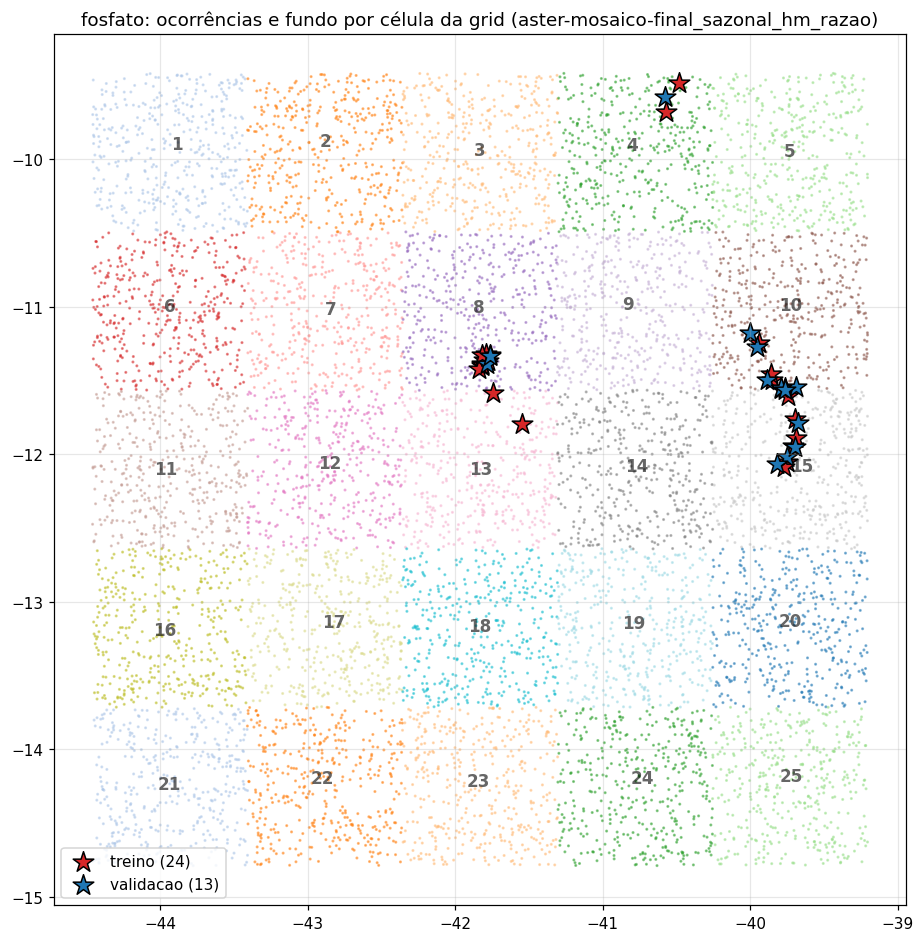

In [8]:
# [5]
cm = plt.get_cmap('tab20')
fig, ax = plt.subplots(figsize=(10, 13))
ax.scatter(FUNDO.lon, FUNDO.lat, s=1, c=[cm(int(c) % 20) for c in FUNDO.celula], alpha=0.5)
for c, g in FUNDO.groupby('celula'):
    ax.text(g.lon.median(), g.lat.median(), str(int(c)), fontsize=11, ha='center', weight='bold', alpha=0.6)
for papel, cor in [('treino', '#d62728'), ('validacao', '#1f77b4')]:
    o = OC[OC.papel == papel]
    ax.scatter(o.lon, o.lat, s=200, marker='*', c=cor, edgecolor='k', label=f'{papel} ({len(o)})')
ax.set_aspect('equal'); ax.legend(loc='lower left')
ax.set_title(f'{ALVO}: ocorrências e fundo por célula da grid ({MOSAICO})')
salvar(fig, '5', f'pontos_{ID_RC}')

`[5a]`

**Figura [6] — cada variável sozinha.** Para cada ocorrência, a mediana da variável
nos seus pixels vira percentil do fundo (0 = menor valor da região, 100 = maior).
Pontos juntos perto de 0 ou 100 = a variável destaca as ocorrências; espalhados em
volta de 50 = não distingue. Ordem: distância da mediana até 50. Só exploração, não
seleciona nada.

figura → c6_percentil_ocorrencias_shm.png


B09                               86.0
B05                               84.0
B07                               84.0
B08                               83.0
B06                               83.0
B02                               83.0
B01                               83.0
B04                               81.0
phosphorite_rbd                   77.0
ferric_ox_4_3                     58.0
B3N                               76.0
sultan_r                          21.0
ferrous_sil_5_4                   78.0
sultan_g                          29.0
alunite_kaolinite_pyrophyllite    26.0
dtype: float64

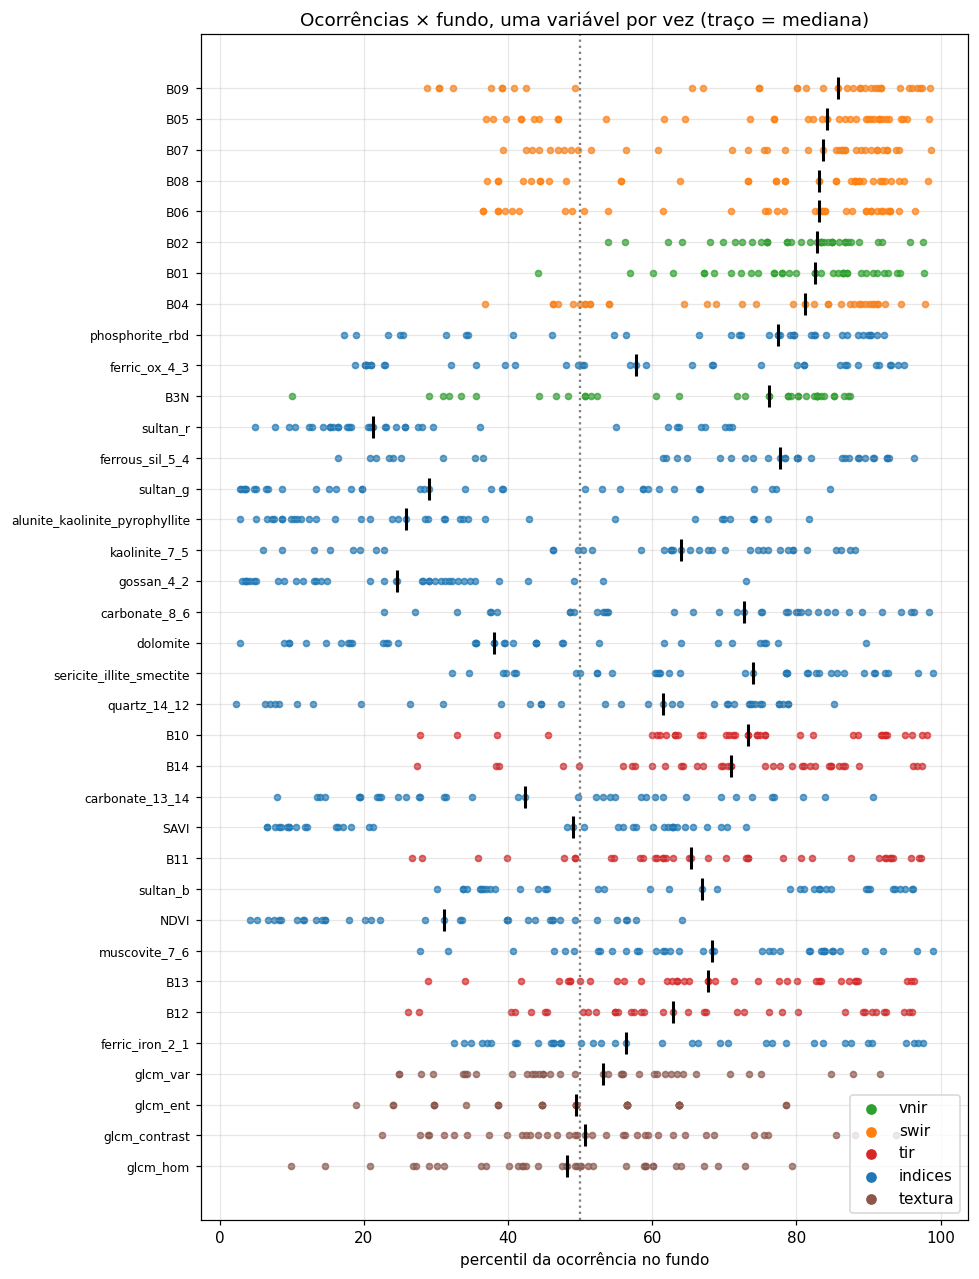

In [9]:
# [6]
med = PRES.groupby('CODIGO_OBJ')[VARS].median()
pct = pd.DataFrame({v: np.searchsorted(np.sort(FUNDO[v].values), med[v].values) / len(FUNDO) * 100 for v in VARS},
                   index=med.index)
ordem = (pct - 50).abs().median().sort_values(ascending=False).index
CORES_G = dict(zip(['vnir', 'swir', 'tir', 'indices', 'textura'],
                   ['#2ca02c', '#ff7f0e', '#d62728', '#1f77b4', '#8c564b']))
cor_v = {v: CORES_G[g] for g in CORES_G for v in G[g]}
fig, ax = plt.subplots(figsize=(9, 14))
for i, v in enumerate(ordem[::-1]):
    ax.scatter(pct[v], np.full(len(pct), i), s=16, c=cor_v[v], alpha=0.7)
    ax.plot(np.median(pct[v]), i, '|', c='k', ms=14, mew=2)
ax.set_yticks(range(len(ordem)), ordem[::-1], fontsize=8)
ax.axvline(50, c='grey', ls=':')
for g, c in CORES_G.items():
    ax.scatter([], [], c=c, label=g)
ax.legend(loc='lower right'); ax.set_xlabel('percentil da ocorrência no fundo')
ax.set_title('Ocorrências × fundo, uma variável por vez (traço = mediana)')
salvar(fig, '6', f'percentil_ocorrencias_{ID_RC}')
pct.median().loc[ordem].round(0).head(15)

`[7]`

## 2. Redundância

Spearman entre as variáveis **no fundo**, ligação completa com distância 1 − |r| e
corte em 1 − `R_MAX`: dentro de cada grupo todo par tem |r| ≥ `R_MAX`. Fica uma por
grupo, pela ordem de `PRIORIDADE` (as 21 do v1, que não usam este mosaico). Exceção:
as bandas de `MANTER` (B02, B3N, B10, B14) ficam sempre; num grupo redundante com
alguma delas, ficam só elas (no VNIR, B02 no lugar de B01; no TIR, B10 e B14 dos cinco). A
redução é feita **sobre a união** das variáveis de cada conjunto da ablação, porque
os índices são razões das bandas e se repetem entre grupos (ex.: B04 e `gossan_4_2`).

Conjuntos (`CONJ_BRUTO`):
- `vnir_tir`: só bandas sem SWIR;
- `bandas`: as 14 bandas;
- `indices`: os índices;
- `bandas_indices`: bandas + índices;
- `todas`: bandas + índices + textura;
- `sem_swir`: VNIR, TIR, índices sem SWIR e textura (nada que dependa do SWIR estimado);
- `fixas_v1`: as 21 do v1, sem nova redução (referência).

**Figura [8].** Dendrograma de todas as variáveis (linha vermelha = |r| = `R_MAX`) e a
matriz de Spearman na mesma ordem.

vnir_tir       : 8 → 4
    B10, B14 ← ['B11', 'B12', 'B13']
    B02 ← ['B01']
bandas         : 14 → 5
    B10, B14 ← ['B11', 'B12', 'B13']
    B02 ← ['B01']
    B09 ← ['B04', 'B05', 'B06', 'B07', 'B08']
indices        : 18 → 13
    SAVI ← ['NDVI', 'sultan_b']
    sultan_r ← ['alunite_kaolinite_pyrophyllite', 'ferrous_sil_5_4']
    quartz_14_12 ← ['carbonate_13_14']
bandas_indices : 32 → 18
    sultan_r ← ['alunite_kaolinite_pyrophyllite', 'ferrous_sil_5_4']
    SAVI ← ['NDVI', 'sultan_b']
    B10, B14 ← ['B11', 'B12', 'B13']
    B02 ← ['B01']
    B09 ← ['B04', 'B05', 'B06', 'B07', 'B08']
    quartz_14_12 ← ['carbonate_13_14']
todas          : 36 → 21
    sultan_r ← ['alunite_kaolinite_pyrophyllite', 'ferrous_sil_5_4']
    SAVI ← ['NDVI', 'sultan_b']
    B10, B14 ← ['B11', 'B12', 'B13']
    B02 ← ['B01']
    B09 ← ['B04', 'B05', 'B06', 'B07', 'B08']
    quartz_14_12 ← ['carbonate_13_14']
    glcm_contrast ← ['glcm_var']
sem_swir       : 18 → 11
    SAVI ← ['NDVI']
    B10, B14 ← ['B11',

PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_selecao_RC/c8_redundancia_shm.png')

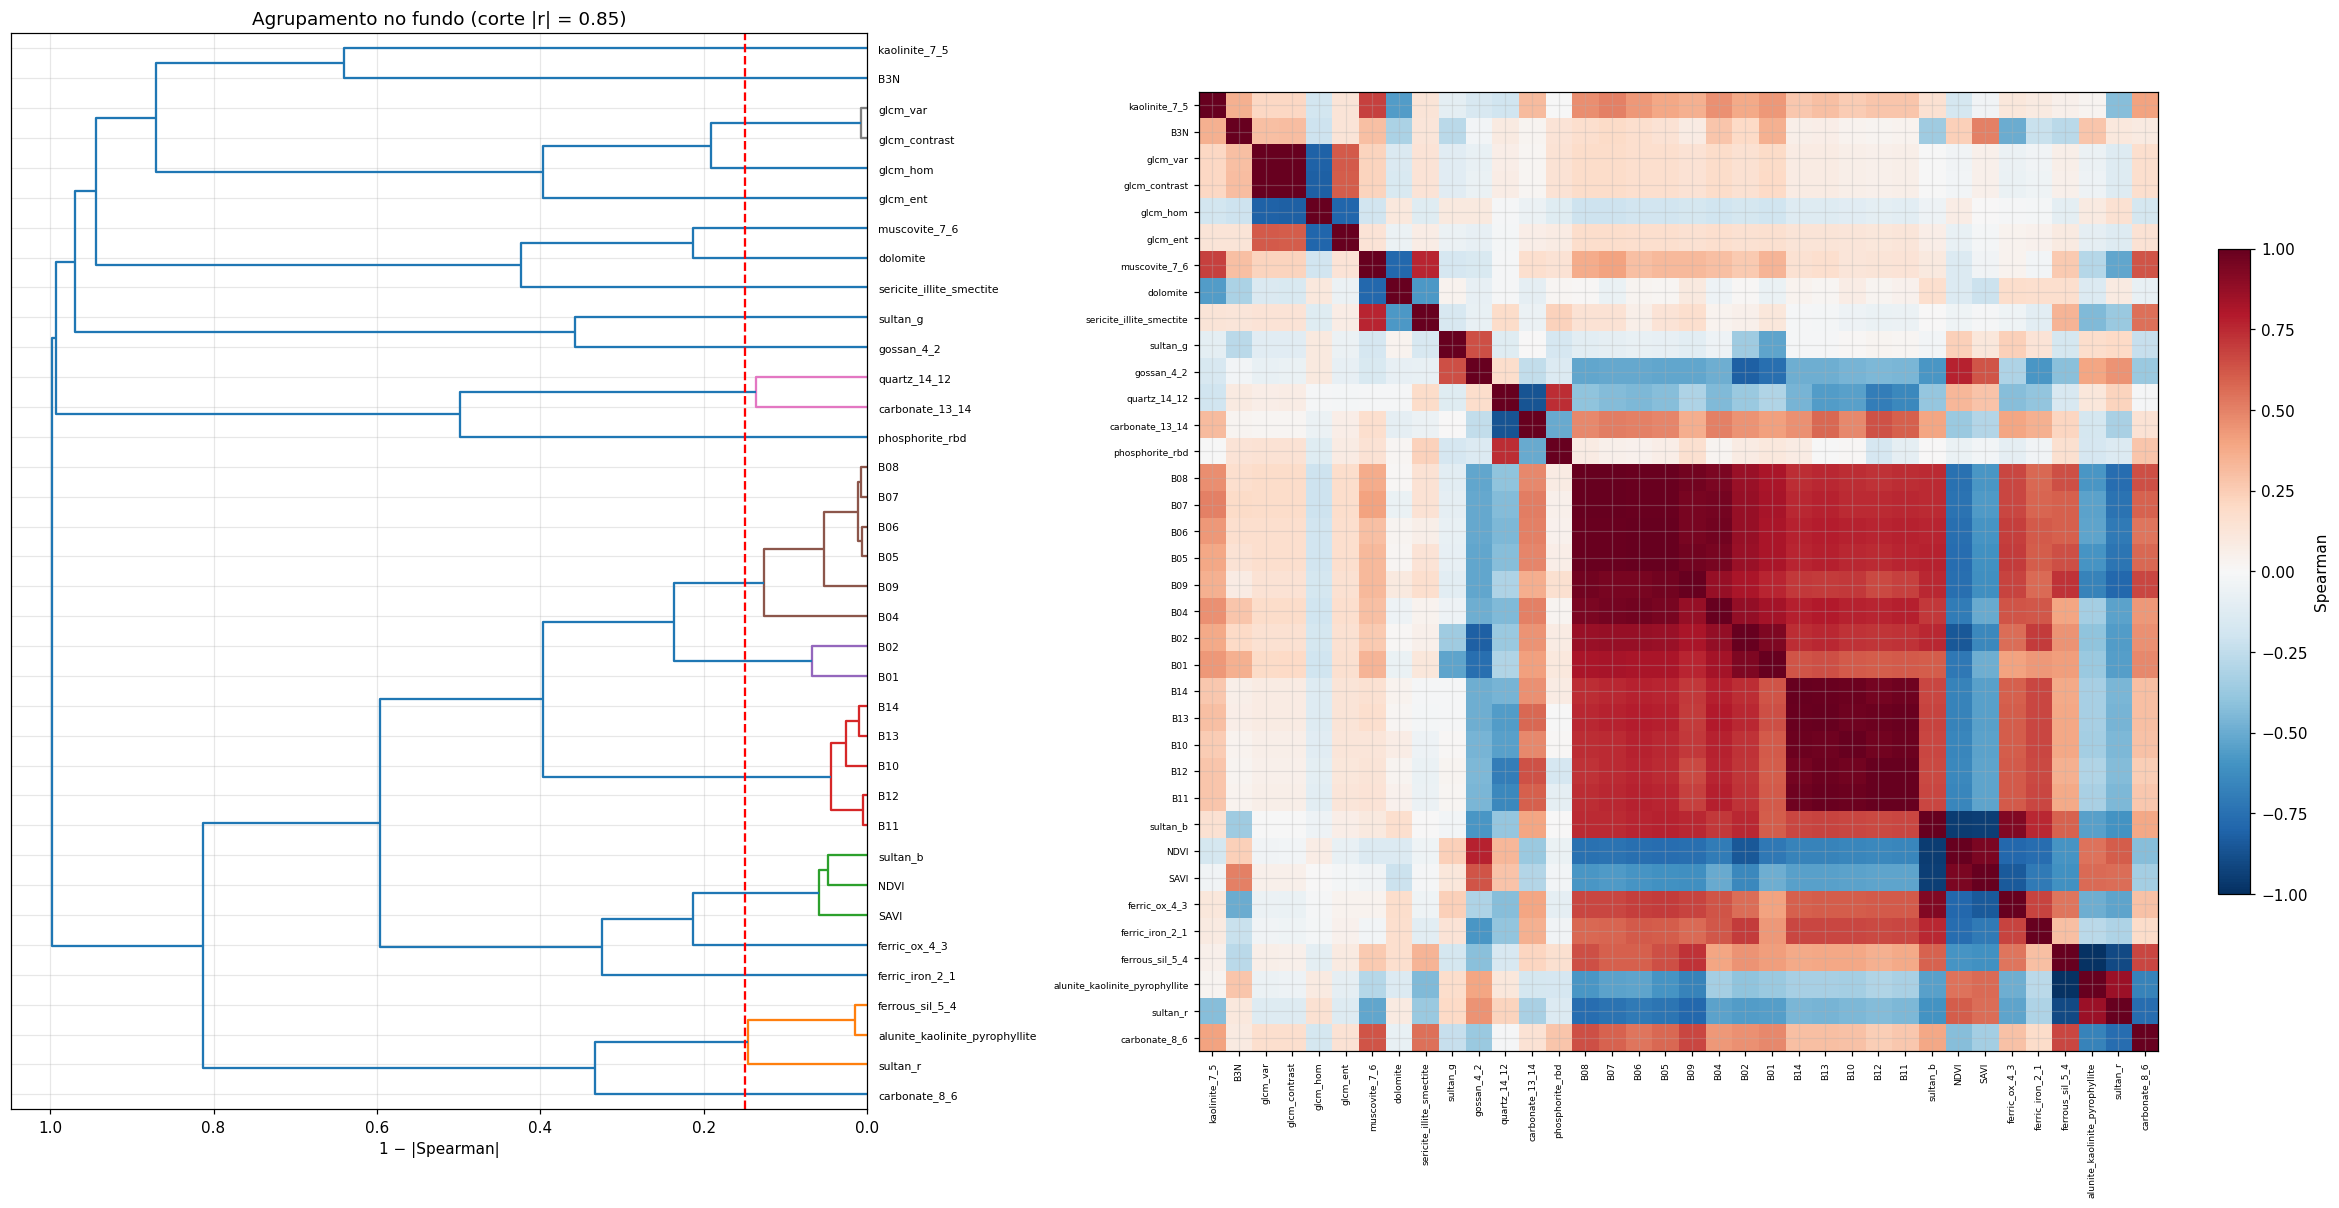

In [10]:
# [8]
# bandas que ficam sempre, mesmo redundantes entre si: num grupo redundante com alguma
# delas, ficam só elas (B02 no lugar de B01; B10 e B14 dos 5 do TIR); grupos sem
# nenhuma seguem a PRIORIDADE. Trocar B10 por B11 aqui, se preferir.
MANTER = ['B02', 'B3N', 'B10', 'B14']

def reduzir(cols, f=FUNDO):
    """(mantidas, grupos {representante: membros}) com |Spearman| ≥ R_MAX no fundo f.
    Num grupo com variáveis de MANTER, todas elas ficam e o representante é a 1ª."""
    cols = [c for c in cols if f[c].nunique() > 1]
    if len(cols) < 2:
        return cols, {c: [c] for c in cols}
    r = f[cols].corr(method='spearman').fillna(0).values
    d = 1 - np.abs(r); np.fill_diagonal(d, 0)
    lab = hierarchy.fcluster(hierarchy.linkage(squareform(d, checks=False), 'complete'), 1 - R_MAX, 'distance')
    grupos, mantidas = {}, []
    for k in np.unique(lab):
        membros = sorted([cols[i] for i in np.where(lab == k)[0]], key=prioridade)
        fixas = [m for m in MANTER if m in membros]
        if fixas:
            membros = fixas + [m for m in membros if m not in fixas]
        grupos[membros[0]] = membros
        mantidas += fixas or membros[:1]
    return sorted(mantidas, key=cols.index), grupos

BANDAS = G['vnir'] + G['swir'] + G['tir']
CONJ_BRUTO = {
    'vnir_tir':       G['vnir'] + G['tir'],
    'bandas':         BANDAS,
    'indices':        G['indices'],
    'bandas_indices': BANDAS + G['indices'],
    'todas':          BANDAS + G['indices'] + G['textura'],
    'sem_swir':       G['vnir'] + G['tir'] + [v for v in G['indices'] if v not in INDICES_SWIR] + G['textura'],
}
CONJ, GRUPOS_RED = {}, {}
for nome, cols in CONJ_BRUTO.items():
    CONJ[nome], GRUPOS_RED[nome] = reduzir(cols)
    juntos = {k: m for k, m in GRUPOS_RED[nome].items() if len(m) > 1}
    fica = lambda m: [v for v in m if v in CONJ[nome]]
    print(f'{nome:15s}: {len(cols)} → {len(CONJ[nome])}' +
          ''.join(f'\n    {", ".join(fica(m))} ← {[v for v in m if v not in CONJ[nome]]}'
                  for m in juntos.values() if len(fica(m)) < len(m)))
CONJ['fixas_v1'] = [v for v in FEATURES_V1 if v in VARS]
VARS_CL = VARS_CLUSTER or CONJ['todas']
print(f'\nVARS_CL (agrupamento do fundo): {len(VARS_CL)} variáveis')

cols = [c for c in VARS if FUNDO[c].nunique() > 1]
r = FUNDO[cols].corr(method='spearman').fillna(0)
d = 1 - r.abs().values; np.fill_diagonal(d, 0)
Z = hierarchy.linkage(squareform(d, checks=False), 'complete')
fig, axs = plt.subplots(1, 2, figsize=(22, 11), gridspec_kw={'width_ratios': [1, 1.4]})
dn = hierarchy.dendrogram(Z, labels=cols, orientation='left', ax=axs[0], color_threshold=1 - R_MAX,
                          leaf_font_size=7)
axs[0].axvline(1 - R_MAX, c='r', ls='--'); axs[0].set_xlabel('1 − |Spearman|')
axs[0].set_title(f'Agrupamento no fundo (corte |r| = {R_MAX})')
ordem = dn['ivl'][::-1]
im = axs[1].imshow(r.loc[ordem, ordem], cmap='RdBu_r', vmin=-1, vmax=1)
axs[1].set_xticks(range(len(ordem)), ordem, rotation=90, fontsize=6)
axs[1].set_yticks(range(len(ordem)), ordem, fontsize=6)
fig.colorbar(im, ax=axs[1], shrink=0.6, label='Spearman')
fig.tight_layout()
salvar(fig, '8', f'redundancia_{ID_RC}')

`[9]`

## 3. Validação espacial por célula da grid

**Folds.** Uma célula da grid 5 × 5 de fora por vez: o modelo treina sem a presença e
sem o fundo da célula e prediz os pixels dela. No fim, todo pixel de presença e de
fundo tem um p de um modelo que não viu a célula. As ocorrências estão em poucas
células; as células só com fundo também saem uma a uma, para todo o fundo ter p fora
da amostra.

**Modelos.** RF e GTB com os parâmetros do `avaliar_maxent.ipynb`; o GEE usa os
mesmos (300 árvores no RF, 80 no GTB com passo 0,1). Aqui com `class_weight =
'balanced'`; no GEE o fundo é sorteado em `FATOR_FUNDO` × a presença.

**Métricas** (fora da amostra), sobre a mediana de p de cada ocorrência:
- `auc_ponto`: ocorrência × fundo, com intervalo de 90% por bootstrap das ocorrências;
- `ap_ganho`: precisão média ÷ prevalência (1 = acaso);
- `boyce`: índice de Boyce contínuo (pixels de presença);
- `top10`: fração das ocorrências nos 10% da área com maior p.

**Figura [10].** Pixels de fundo e de presença por célula (= fold).

figura → c10_folds_shm.png


,ocorrencias,px_presenca,px_fundo
celula,,,
4,3,60,400
8,11,220,400
10,11,220,400
13,2,40,400
15,10,200,400


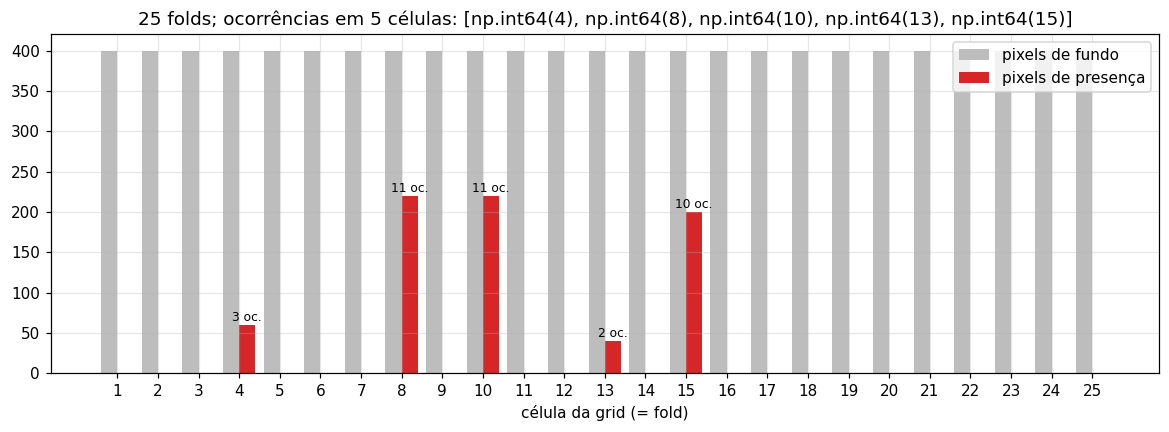

In [11]:
# [10]
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=10, max_features='sqrt',
                 class_weight='balanced', n_jobs=-1, random_state=SEED)
GTB_PARAMS = dict(learning_rate=0.1, max_iter=80, max_depth=4, min_samples_leaf=50,
                  l2_regularization=1.0, class_weight='balanced', random_state=SEED)

class RFPresFundo:
    def fit(self, Xp, Xf):
        self.rf = RandomForestClassifier(**RF_PARAMS).fit(np.r_[Xp, Xf], np.r_[np.ones(len(Xp)), np.zeros(len(Xf))])
        return self
    def predict(self, X):
        return self.rf.predict_proba(X)[:, 1]

class GTBPresFundo:
    def fit(self, Xp, Xf):
        self.gb = HistGradientBoostingClassifier(**GTB_PARAMS).fit(np.r_[Xp, Xf], np.r_[np.ones(len(Xp)), np.zeros(len(Xf))])
        return self
    def predict(self, X):
        return self.gb.predict_proba(X)[:, 1]

MODELOS_CLS = {'RF': RFPresFundo, 'GTB': GTBPresFundo}
COR_MOD = {'RF': 'k', 'GTB': '#17becf'}

_CACHE_CL = {}

def agrupar_fundo(p_tr, f_tr):
    """k-means (K_FUNDO) do fundo nas VARS_CL padronizadas no fundo e distância de cada
    cluster ao "cluster fosfato" (centro = média das medianas de cada ocorrência no mesmo
    espaço). Não depende das variáveis do modelo: fica em cache por fold."""
    chave = (tuple(sorted(p_tr.CODIGO_OBJ.unique())), len(f_tr), int(f_tr.index.values.sum()), K_FUNDO,
             tuple(VARS_CL))
    if chave in _CACHE_CL:
        return _CACHE_CL[chave]
    cols = VARS_CL
    sc = StandardScaler().fit(f_tr[cols])
    km = KMeans(K_FUNDO, n_init=10, random_state=SEED).fit(sc.transform(f_tr[cols]))
    lab, centros = km.labels_, km.cluster_centers_
    med = sc.transform(p_tr.groupby('CODIGO_OBJ')[cols].median())
    c_oc = med.mean(0)
    raio = np.linalg.norm(med - c_oc, axis=1).max()
    lab_oc = np.linalg.norm(med[:, None] - centros[None], axis=2).argmin(1)
    res = {'cols': cols, 'centros': pd.DataFrame(centros, columns=cols), 'c_oc': pd.Series(c_oc, index=cols),
           'dist': np.linalg.norm(centros - c_oc, axis=1), 'raio': raio,
           'n_oc': np.bincount(lab_oc, minlength=K_FUNDO), 'frac': np.bincount(lab, minlength=K_FUNDO) / len(lab),
           'lab': pd.Series(lab, index=f_tr.index), 'media': sc.mean_, 'desvio': sc.scale_}
    _CACHE_CL[chave] = res
    return res

def fundo_treino(p_tr, f_tr, modo=None, info=False):
    """Fundo do TREINO. 'aleatorio' = todo. 'cluster' = só os clusters mais distantes do
    cluster fosfato, sem ocorrência, pela REGRA_FUNDO:
      'n_distantes' — os N_CLUSTERS_FUNDO de maior distância;
      'raio'        — todos com o centro além do raio do fosfato.
    Se somarem menos de FRAC_MIN_FUNDO do fundo, entram os próximos mais distantes sem
    ocorrência ('completou'). Usa só as ocorrências de treino (p_tr)."""
    modo = modo or FUNDO_MODO
    if modo == 'aleatorio':
        return (f_tr, None) if info else f_tr
    r = agrupar_fundo(p_tr, f_tr)
    dist, frac, n_oc = r['dist'], r['frac'], r['n_oc']
    if REGRA_FUNDO == 'n_distantes':
        cand = [c for c in np.argsort(-dist) if n_oc[c] == 0][:N_CLUSTERS_FUNDO]
        longe = np.isin(np.arange(len(dist)), cand)
    else:
        longe = (dist > r['raio']) & (n_oc == 0)
    completou = np.zeros_like(longe)
    if frac[longe].sum() < FRAC_MIN_FUNDO:
        for c in np.argsort(-dist):
            if n_oc[c] == 0 and not longe[c]:
                longe[c] = completou[c] = True
                if frac[longe].sum() >= FRAC_MIN_FUNDO:
                    break
    sel = f_tr[longe[r['lab'].values]]
    return (sel, {**r, 'longe': longe, 'completou': completou}) if info else sel

def oof(p, f, feats, Modelo, celulas=None):
    """p fora da amostra, uma célula da grid de fora por vez. celulas = None: todas
    (presença e fundo); senão só essas. O treino usa o fundo de fundo_treino; a predição
    e as métricas, TODO o fundo da célula."""
    op, of = pd.Series(np.nan, index=p.index), pd.Series(np.nan, index=f.index)
    for c in celulas if celulas is not None else sorted(set(p.celula) | set(f.celula)):
        p_tr = p[p.celula != c]
        m = Modelo().fit(p_tr[feats].values, fundo_treino(p_tr, f[f.celula != c])[feats].values)
        if (p.celula == c).any():
            op[p.celula == c] = m.predict(p.loc[p.celula == c, feats].values)
        if (f.celula == c).any():
            of[f.celula == c] = m.predict(f.loc[f.celula == c, feats].values)
    return op, of

def boyce(pp, pf, n_janelas=91, largura=0.1):
    """Boyce contínuo com janelas de área igual (mesmo do avaliar_maxent)."""
    u = np.searchsorted(np.sort(pf), pp) / len(pf)
    cent = np.linspace(largura / 2, 1 - largura / 2, n_janelas)
    pe = np.array([((u >= c - largura / 2) & (u < c + largura / 2)).mean() / largura for c in cent])
    return spearmanr(cent, pe).statistic

def metricas(op, of, p):
    op, of = op.dropna(), of.dropna()
    pp, pf = op.values, of.values
    pt = op.groupby(p.loc[op.index, 'CODIGO_OBJ']).median().values
    y = np.r_[np.ones(len(pt)), np.zeros(len(pf))]
    auc = roc_auc_score(y, np.r_[pt, pf])
    boot = [roc_auc_score(y, np.r_[rng.choice(pt, len(pt)), pf]) for _ in range(N_BOOT)]
    return {'auc_ponto': auc, 'auc_p05': np.quantile(boot, 0.05), 'auc_p95': np.quantile(boot, 0.95),
            'ap_ganho': average_precision_score(y, np.r_[pt, pf]) / y.mean(),
            'boyce': boyce(pp, pf), 'top10': (pt >= np.quantile(pf, 0.9)).mean(), 'ocorrencias': len(pt)}

CEL_PRES = sorted(PRES.celula.unique())
tab = pd.DataFrame({'ocorrencias': PRES.groupby('celula').CODIGO_OBJ.nunique(),
                    'px_presenca': PRES.celula.value_counts(), 'px_fundo': FUNDO.celula.value_counts()}
                   ).fillna(0).astype(int).sort_index()
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(tab.index - 0.2, tab.px_fundo, 0.4, color='#bdbdbd', label='pixels de fundo')
ax.bar(tab.index + 0.2, tab.px_presenca, 0.4, color='#d62728', label='pixels de presença')
for c, row in tab[tab.ocorrencias > 0].iterrows():
    ax.text(c + 0.2, row.px_presenca + 5, f'{row.ocorrencias} oc.', ha='center', fontsize=8)
ax.set_xticks(tab.index); ax.set_xlabel('célula da grid (= fold)'); ax.legend()
ax.set_title(f'{len(tab)} folds; ocorrências em {len(CEL_PRES)} células: {CEL_PRES}')
salvar(fig, '10', f'folds_{ID_RC}')
tab[tab.ocorrencias > 0]

`[10a]`

**Fundo por cluster (`FUNDO_MODO = 'cluster'`).** O fundo aleatório inclui pixels
parecidos com as ocorrências (a mesma rocha sem depósito conhecido, ou com depósito
ainda não achado). Treinar com eles como "não fosfato" empurra o modelo a separar
detalhes finos e ruidosos. Pseudo-ausência por perfil ambiental (Engler et al. 2004;
Senay et al. 2013), igual à área reduzida:
1. k-means do fundo em `K_FUNDO` clusters nas `VARS_CL` padronizadas no fundo;
2. **cluster fosfato** = centro na média das medianas de cada ocorrência;
3. distância de cada cluster = euclidiana do seu centro ao centro do fosfato;
4. **raio do fosfato** = distância da ocorrência mais afastada ao centro;
5. no fundo de treino ficam só os clusters mais distantes, sem ocorrência
   (`REGRA_FUNDO`):
   - `'n_distantes'` (padrão): os **`N_CLUSTERS_FUNDO` = 2 clusters mais distantes** do
     cluster fosfato;
   - `'raio'`: todos os clusters além do raio do fosfato (a regra que está no código do AR;
     lá ela deu 3 clusters além do raio + 1 para completar 20%).
   Se os escolhidos somarem menos de `FRAC_MIN_FUNDO` do fundo, entram os próximos mais
   distantes sem ocorrência (hachurado). Isso evita treinar com um cluster pequeno de
   valores extremos (água, sombra, resto de nuvem): com 740 pixels de presença, o
   export precisa de `FATOR_FUNDO` × 740 = 2.220 pixels de fundo elegíveis.

Na validação o agrupamento é refeito dentro de cada fold, só com as ocorrências de
treino. Só o **treino** usa o fundo filtrado: AUC, Boyce e top10 são sempre medidos
contra todo o fundo da célula de fora. Para comparar, rode o notebook com
`'aleatorio'` e com `'cluster'`: figuras e CSVs levam o modo no nome.

**Figura [10b].** Com todas as ocorrências. Esquerda: cinza = fundo de treino, laranja
= excluído. Direita: clusters do mais próximo ao mais distante do fosfato (vermelho =
tem ocorrência, laranja = excluído, cinza = treino, hachurado = entrou para completar
`FRAC_MIN_FUNDO`); tracejado = raio.

regra n_distantes (N = 2); clusters de treino [0, 2, 5, 7, 8, 9], completou [0, 5, 7, 9]
k-means: 10 clusters em 21 variáveis; raio do fosfato 4.42; fundo de treino 3834 de 10000 px (38%); clusters com ocorrência: [1, 3, 4, 6]
figura → c10b_fundo_cluster_shm_k10_n_distantes.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_selecao_RC/c10b_fundo_cluster_shm_k10_n_distantes.png')

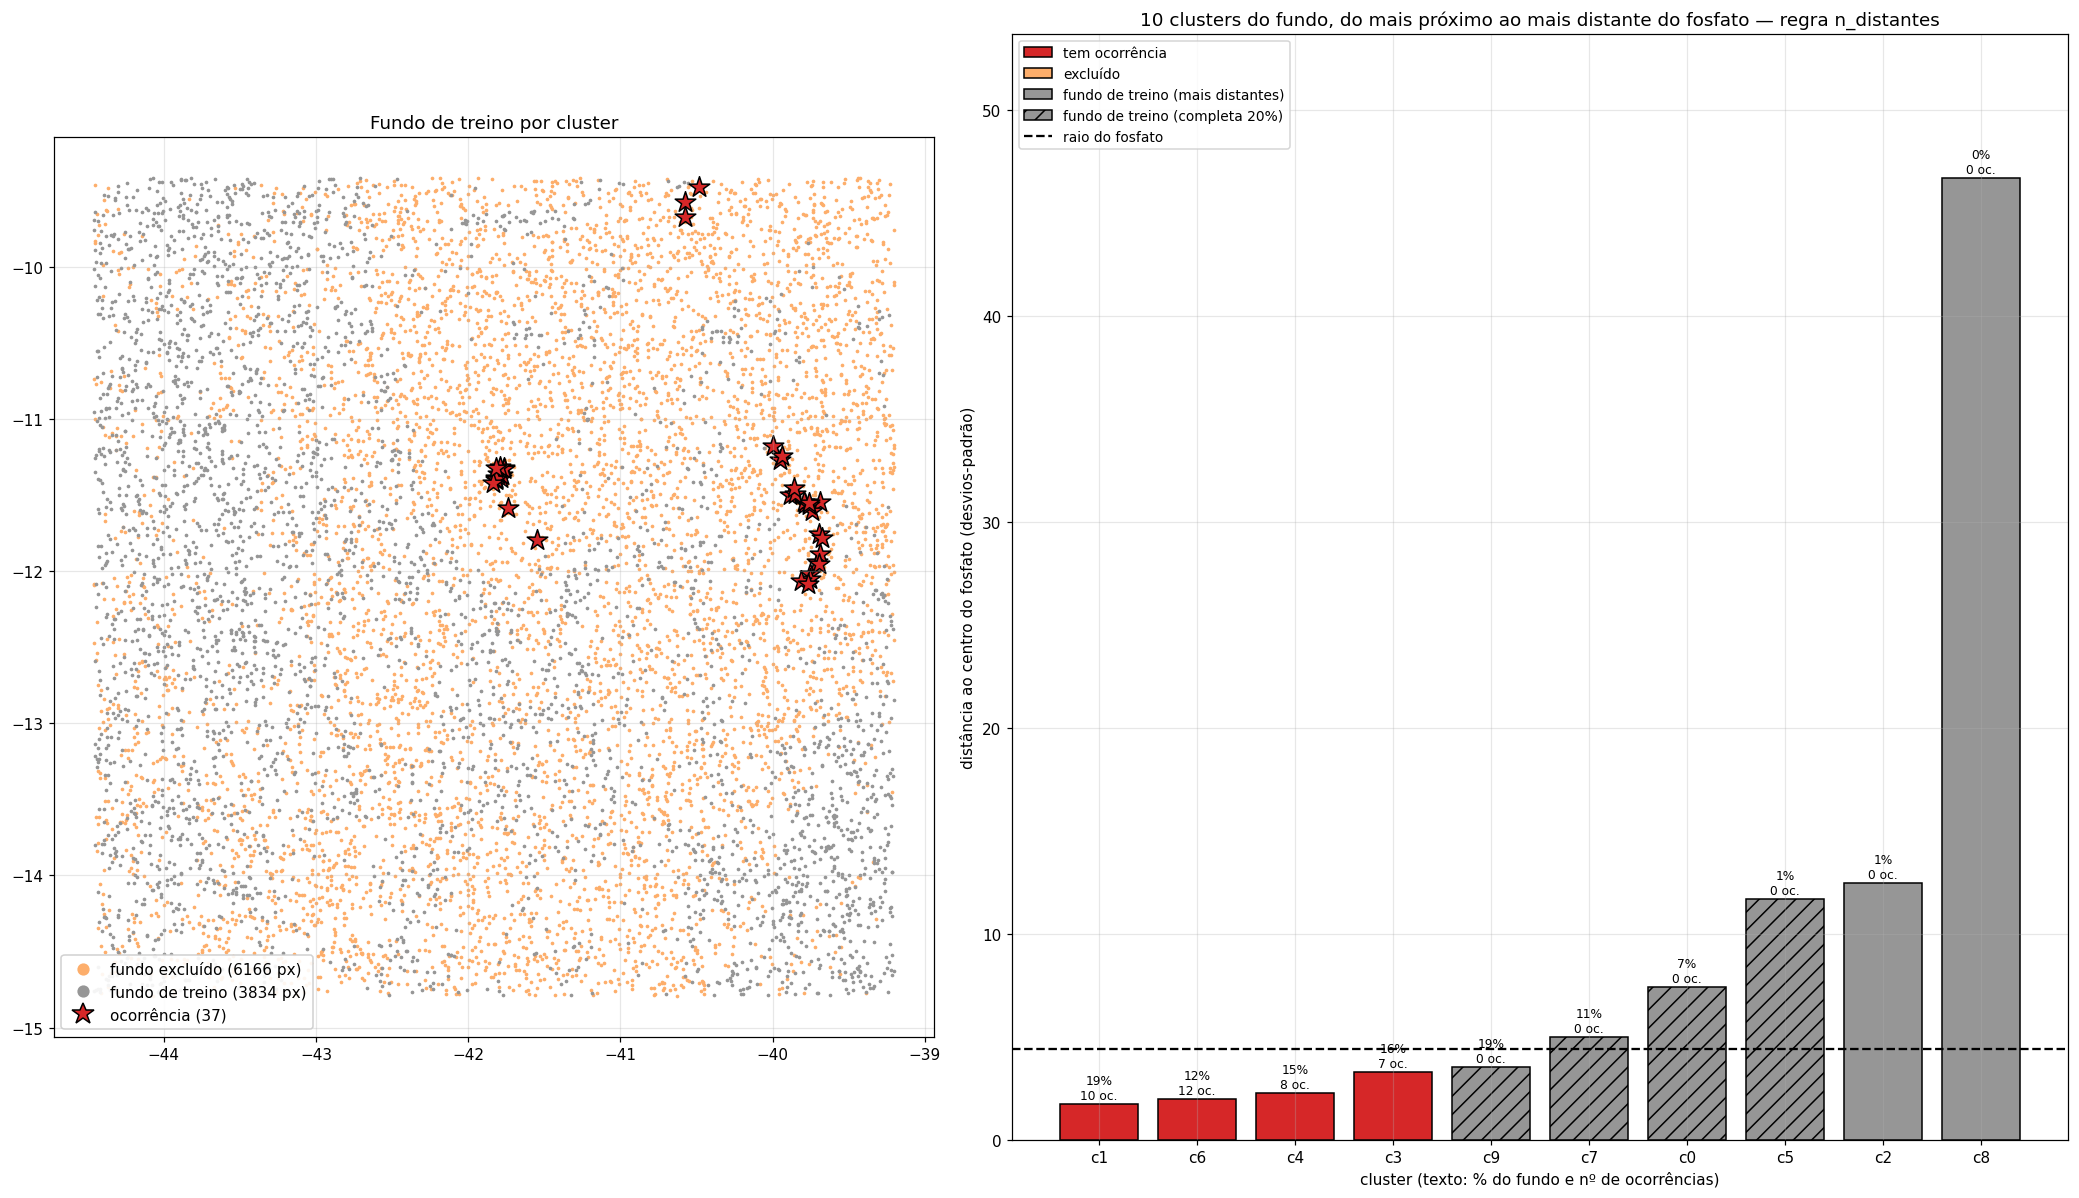

In [12]:
# [10b]
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sel, inf = fundo_treino(PRES, FUNDO, modo='cluster', info=True)
K_CL = len(inf['dist'])
fica = FUNDO.index.isin(sel.index)
print(f'regra {REGRA_FUNDO}' + (f' (N = {N_CLUSTERS_FUNDO})' if REGRA_FUNDO == 'n_distantes' else '') +
      f'; clusters de treino {np.where(inf["longe"])[0].tolist()}, completou {np.where(inf["completou"])[0].tolist()}')
print(f'k-means: {K_CL} clusters em {len(inf["cols"])} variáveis; raio do fosfato {inf["raio"]:.2f}; '
      f'fundo de treino {fica.sum()} de {len(FUNDO)} px ({fica.mean():.0%}); '
      f'clusters com ocorrência: {np.where(inf["n_oc"] > 0)[0].tolist()}')

C_EXC, C_TR, C_OC = '#fdae6b', '#969696', '#d62728'
fig, axs = plt.subplots(1, 2, figsize=(19, 11), gridspec_kw={'width_ratios': [1, 1.2]})
ax = axs[0]
ax.scatter(FUNDO.lon[~fica], FUNDO.lat[~fica], s=2, c=C_EXC)
ax.scatter(FUNDO.lon[fica], FUNDO.lat[fica], s=2, c=C_TR)
ax.scatter(OC.lon, OC.lat, s=200, marker='*', c=C_OC, edgecolor='k')
ax.legend(handles=[
    Line2D([], [], ls='', marker='o', ms=7, color=C_EXC, label=f'fundo excluído ({(~fica).sum()} px)'),
    Line2D([], [], ls='', marker='o', ms=7, color=C_TR, label=f'fundo de treino ({fica.sum()} px)'),
    Line2D([], [], ls='', marker='*', ms=15, mfc=C_OC, mec='k', label=f'ocorrência ({len(OC)})'),
], loc='lower left', fontsize=10, framealpha=0.9)
ax.set_aspect('equal'); ax.set_title('Fundo de treino por cluster')

ax = axs[1]
ordem = np.argsort(inf['dist'])
for j, c in enumerate(ordem):
    cor = C_OC if inf['n_oc'][c] else (C_TR if inf['longe'][c] else C_EXC)
    ax.bar(j, inf['dist'][c], color=cor, edgecolor='k', hatch='//' if inf['completou'][c] else None)
    ax.text(j, inf['dist'][c] + 0.1, f"{inf['frac'][c]:.0%}\n{inf['n_oc'][c]} oc.", ha='center', va='bottom', fontsize=8)
ax.axhline(inf['raio'], c='k', ls='--')
ax.set_xticks(range(K_CL), [f'c{c}' for c in ordem])
ax.set_xlabel('cluster (texto: % do fundo e nº de ocorrências)')
ax.set_ylabel('distância ao centro do fosfato (desvios-padrão)')
ax.legend(handles=[Patch(fc=C_OC, ec='k', label='tem ocorrência'), Patch(fc=C_EXC, ec='k', label='excluído'),
                   Patch(fc=C_TR, ec='k', label='fundo de treino (mais distantes)'),
                   Patch(fc=C_TR, ec='k', hatch='//', label=f'fundo de treino (completa {FRAC_MIN_FUNDO:.0%})'),
                   Line2D([], [], c='k', ls='--', label='raio do fosfato')], loc='upper left', fontsize=9)
ax.set_ylim(0, max(inf['dist'].max(), inf['raio']) * 1.15)
ax.set_title(f'{K_CL} clusters do fundo, do mais próximo ao mais distante do fosfato — regra {REGRA_FUNDO}')
fig.tight_layout()
salvar(fig, '10b', f'fundo_cluster_{ID_RC}_k{K_CL}_{REGRA_FUNDO}')

`[10c]`

**Tabela [10c] — clusters**, do mais próximo ao mais distante do fosfato:
`dist_fosfato` (desvios-padrão), `variavel_dominante` e `parcela_dominante` (fração da
distância² que vem dela) e `situacao` (ocorrência, excluído, treino = um dos mais
distantes, treino_completa = entrou para completar `FRAC_MIN_FUNDO`). Os clusters de
treino são as últimas linhas.
A coluna `celulas` mostra em quantas células o cluster aparece: um cluster que só
existe em uma ou duas células pode ser efeito de cena (limite de cena ou de período
A/B), não de rocha.

In [13]:
# [10c]
dif2 = (inf['centros'] - inf['c_oc']) ** 2
lab = inf['lab']
TAB_CL = pd.DataFrame({
    'pixels': lab.value_counts().reindex(range(K_CL), fill_value=0).values,
    'pct_fundo': (inf['frac'] * 100).round(1),
    'celulas': FUNDO.loc[lab.index].groupby(lab.values).celula.nunique().reindex(range(K_CL), fill_value=0).values,
    'pct_origem_A': (FUNDO.loc[lab.index].origem.eq(1).groupby(lab.values).mean() * 100).reindex(range(K_CL)).round(0).values,
    'ocorrencias': inf['n_oc'],
    'dist_fosfato': inf['dist'],
    'variavel_dominante': dif2.idxmax(1).values,
    'parcela_dominante': (dif2.max(1) / dif2.sum(1)).values,
    'situacao': np.select([inf['n_oc'] > 0, inf['completou'], inf['longe']],
                          ['ocorrência', 'treino_completa', 'treino'], 'excluído'),
}, index=[f'c{c}' for c in range(K_CL)]).sort_values('dist_fosfato')
print(f'raio do fosfato {inf["raio"]:.2f}')
print({k: f'{v} clusters, {TAB_CL.pct_fundo[TAB_CL.situacao == k].sum():.0f}% do fundo'
       for k, v in TAB_CL.situacao.value_counts().items()})
TAB_CL.round(2)

raio do fosfato 4.42
{'ocorrência': '4 clusters, 62% do fundo', 'treino_completa': '4 clusters, 38% do fundo', 'treino': '2 clusters, 0% do fundo'}


,pixels,pct_fundo,celulas,pct_origem_A,ocorrencias,dist_fosfato,variavel_dominante,parcela_dominante,situacao
c1,1920,19.2,25,54.0,10,1.75,quartz_14_12,0.36,ocorrência
c6,1180,11.8,24,51.0,12,1.96,phosphorite_rbd,0.19,ocorrência
c4,1502,15.0,23,68.0,8,2.25,B3N,0.23,ocorrência
c3,1564,15.6,25,54.0,7,3.31,B10,0.17,ocorrência
c9,1883,18.8,25,87.0,0,3.51,B09,0.13,treino_completa
c7,1075,10.8,24,95.0,0,4.98,B09,0.14,treino_completa
c0,673,6.7,22,42.0,0,7.41,gossan_4_2,0.15,treino_completa
c5,148,1.5,10,26.0,0,11.70,glcm_ent,0.32,treino_completa
c2,53,0.5,9,62.0,0,12.45,sericite_illite_smectite,0.31,treino
c8,2,0.0,2,100.0,0,46.71,dolomite,0.61,treino


`[10d]`

**Tabela [10d] — amostras por etapa**, nas células com ocorrência: presença de treino,
fundo disponível, fundo de treino (depois do filtro) e fundo de avaliação (todo o
fundo da célula de fora). A linha `export` é o que o GEE usa: `FATOR_FUNDO` × a
presença, sorteado entre os elegíveis.

In [14]:
# [10d]
CONT = []
for c in CEL_PRES:
    p_tr, f_tr = PRES[PRES.celula != c], FUNDO[FUNDO.celula != c]
    CONT.append({'etapa': f'célula {c}', 'ocorrencias_teste': PRES[PRES.celula == c].CODIGO_OBJ.nunique(),
                 'pres_treino': len(p_tr), 'fundo_disponivel': len(f_tr),
                 'fundo_treino': len(fundo_treino(p_tr, f_tr)), 'fundo_avaliacao': int((FUNDO.celula == c).sum())})
eleg = len(fundo_treino(PRES, FUNDO))
CONT.append({'etapa': 'export', 'ocorrencias_teste': 0, 'pres_treino': len(PRES), 'fundo_disponivel': len(FUNDO),
             'fundo_treino': min(eleg, FATOR_FUNDO * len(PRES)), 'fundo_avaliacao': 0})
CONT = pd.DataFrame(CONT).set_index('etapa')
CONT['pct_fundo_treino'] = (100 * CONT.fundo_treino / CONT.fundo_disponivel).round(0)
print(f'fundo elegível com todas as ocorrências: {eleg} de {len(FUNDO)} px; '
      f'o export sorteia min({FATOR_FUNDO} × {len(PRES)}, {eleg})')
CONT

fundo elegível com todas as ocorrências: 3834 de 10000 px; o export sorteia min(3 × 740, 3834)


,ocorrencias_teste,pres_treino,fundo_disponivel,fundo_treino,fundo_avaliacao,pct_fundo_treino
etapa,,,,,,
célula 4,3,680,9600,3779,400,39.0
célula 8,11,520,9600,2692,400,28.0
célula 10,11,520,9600,1969,400,21.0
célula 13,2,700,9600,3605,400,38.0
célula 15,10,540,9600,2431,400,25.0
export,0,740,10000,2220,0,22.0


`[10e]`

**Cluster do fundo para o GEE.** Grava `models/cluster_fundo_RC_<sufixo>.json` com o
k-means da [10b] (todas as ocorrências): média e desvio de cada variável de `VARS_CL`,
os centros padronizados e os clusters de treino. O `exportar_favorabilidade_ml.py`
padroniza cada pixel de fundo do asset de amostras com essa média e desvio, leva ao
centro mais próximo e treina só com os clusters de treino (nome do asset com `_fcl`).
Só é lido se a [21] gravar `fundo_modo = 'cluster'`.

In [15]:
# [10e]
_, inf = fundo_treino(PRES, FUNDO, modo='cluster', info=True)
CLUSTER_GEE = {
    'mosaico': MOSAICO, 'id': ID_RC, 'alvo': ALVO, 'papeis': PAPEIS, 'k': int(len(inf['dist'])),
    'regra': REGRA_FUNDO, 'n_clusters_fundo': N_CLUSTERS_FUNDO, 'frac_min_fundo': FRAC_MIN_FUNDO,
    'clusters_completou': [int(c) for c in np.where(inf['completou'])[0]],
    'variaveis': list(inf['cols']),
    'media': [float(x) for x in inf['media']], 'desvio': [float(x) for x in inf['desvio']],
    'centros': inf['centros'].values.round(6).tolist(),
    'clusters_treino': [int(c) for c in np.where(inf['longe'])[0]],
    'dist_fosfato': [round(float(x), 4) for x in inf['dist']], 'raio': round(float(inf['raio']), 4),
    'n_ocorrencias': [int(x) for x in inf['n_oc']],
    'pixels_fundo': int(len(FUNDO)), 'pixels_treino': int(inf['longe'][inf['lab'].values].sum()),
}
arq_cl = MODELS / f'cluster_fundo_RC_{ID_RC}.json'
arq_cl.write_text(json.dumps(CLUSTER_GEE, indent=1))
print(f'→ {arq_cl.name}: K = {CLUSTER_GEE["k"]}, regra {REGRA_FUNDO}, clusters de treino {CLUSTER_GEE["clusters_treino"]}, '
      f'{CLUSTER_GEE["pixels_treino"]} de {CLUSTER_GEE["pixels_fundo"]} px de fundo')

→ cluster_fundo_RC_shm.json: K = 10, regra n_distantes, clusters de treino [0, 2, 5, 7, 8, 9], 3834 de 10000 px de fundo


`[11]`

## 4. Ablação por grupo de variáveis

Cada conjunto da [8] (já sem redundância), RF e GTB, célula de fora. Perguntas:
- `vnir_tir` × `bandas`: o SWIR (medido no A, estimado no B) acrescenta algo?
- `bandas` × `indices` × `bandas_indices`: razões ou bandas brutas?
- `todas` × `bandas_indices`: a textura ajuda?
- `sem_swir`: o mapa fica tão bom sem nada que dependa do SWIR estimado? Se sim, é o
  conjunto mais robusto a limites de período A/B;
- `fixas_v1`: as 21 do v1 no mosaico novo (referência para comparar com o v1).

**Figura [12].** AUC por ponto (intervalo de 90% do bootstrap), Boyce e top10; preto
RF, ciano GTB. **Regra de decisão**: um conjunto ganha quando as três métricas sobem e
o intervalo da AUC sobe junto. Com ~37 ocorrências, cada ocorrência vale ~0,03 de
top10; diferenças de AUC abaixo de ~0,03 não decidem.

Demora: 7 conjuntos × 2 modelos × 25 células.

vnir_tir        RF   AUC 0.737 [0.69–0.78]  Boyce 0.89  top10 0.14
vnir_tir        GTB  AUC 0.750 [0.70–0.80]  Boyce 0.90  top10 0.24
bandas          RF   AUC 0.689 [0.65–0.73]  Boyce 0.86  top10 0.08
bandas          GTB  AUC 0.648 [0.59–0.71]  Boyce 0.87  top10 0.08
indices         RF   AUC 0.618 [0.55–0.69]  Boyce 0.56  top10 0.11
indices         GTB  AUC 0.577 [0.52–0.64]  Boyce 0.49  top10 0.11
bandas_indices  RF   AUC 0.687 [0.64–0.73]  Boyce 0.78  top10 0.08
bandas_indices  GTB  AUC 0.635 [0.59–0.68]  Boyce 0.62  top10 0.11
todas           RF   AUC 0.709 [0.66–0.76]  Boyce 0.87  top10 0.16
todas           GTB  AUC 0.692 [0.63–0.75]  Boyce 0.89  top10 0.19
sem_swir        RF   AUC 0.759 [0.71–0.81]  Boyce 0.98  top10 0.32
sem_swir        GTB  AUC 0.764 [0.71–0.81]  Boyce 0.93  top10 0.35
fixas_v1        RF   AUC 0.683 [0.63–0.74]  Boyce 0.77  top10 0.16
fixas_v1        GTB  AUC 0.682 [0.63–0.74]  Boyce 0.88  top10 0.14
figura → c12_ablacao_shm_cluster.png


auc_ponto         boyce         top10       
modelo               GTB     RF    GTB     RF    GTB     RF
conjunto                                                   
vnir_tir           0.750  0.737  0.902  0.887  0.243  0.135
bandas             0.648  0.689  0.867  0.858  0.081  0.081
indices            0.577  0.618  0.494  0.562  0.108  0.108
bandas_indices     0.635  0.687  0.615  0.782  0.108  0.081
todas              0.692  0.709  0.888  0.866  0.189  0.162
sem_swir           0.764  0.759  0.934  0.985  0.351  0.324
fixas_v1           0.682  0.683  0.883  0.774  0.135  0.162

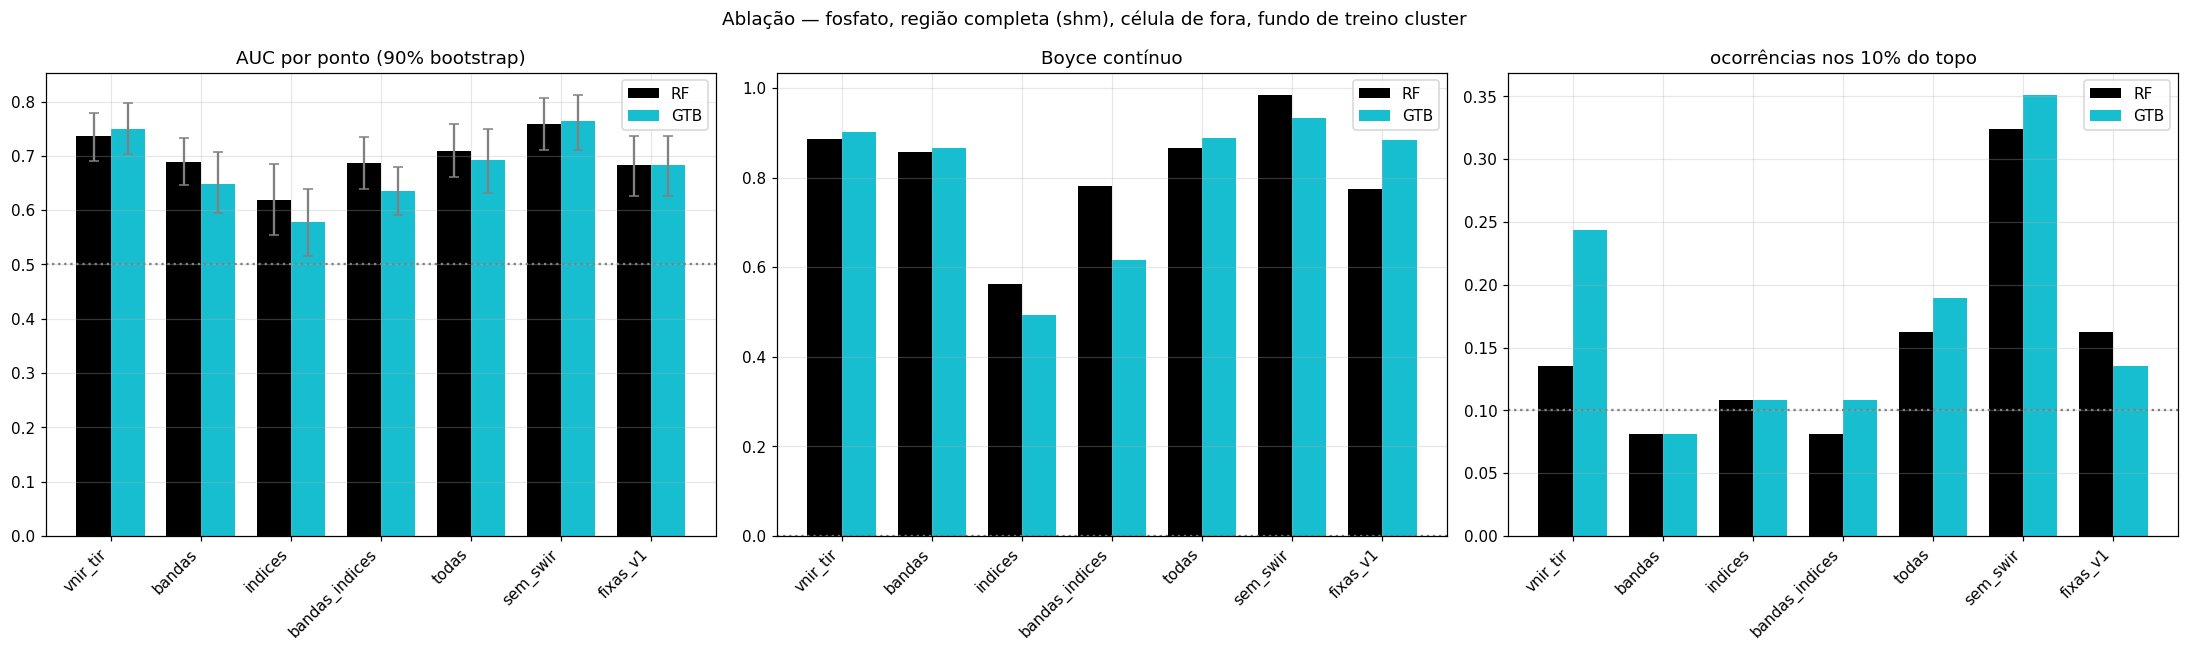

In [16]:
# [12]
OOF, linhas = {}, []
for nome, feats in CONJ.items():
    for mod, Cls in MODELOS_CLS.items():
        op, of = oof(PRES, FUNDO, feats, Cls)
        OOF[(nome, mod)] = (op, of)
        linhas.append({'conjunto': nome, 'modelo': mod, 'variaveis': len(feats), **metricas(op, of, PRES)})
        l = linhas[-1]
        print(f'{nome:15s} {mod:4s} AUC {l["auc_ponto"]:.3f} [{l["auc_p05"]:.2f}–{l["auc_p95"]:.2f}]  '
              f'Boyce {l["boyce"]:.2f}  top10 {l["top10"]:.2f}')
ABL = pd.DataFrame(linhas)

fig, axs = plt.subplots(1, 3, figsize=(20, 6))
x = np.arange(len(CONJ)); w = 0.38
for k, mod in enumerate(MODELOS_CLS):
    t = ABL[ABL.modelo == mod].set_index('conjunto').loc[list(CONJ)]
    axs[0].bar(x + (k - 0.5) * w, t.auc_ponto, w, color=COR_MOD[mod], label=mod,
               yerr=[t.auc_ponto - t.auc_p05, t.auc_p95 - t.auc_ponto], capsize=3, ecolor='grey')
    axs[1].bar(x + (k - 0.5) * w, t.boyce, w, color=COR_MOD[mod], label=mod)
    axs[2].bar(x + (k - 0.5) * w, t.top10, w, color=COR_MOD[mod], label=mod)
for ax, tit, ref in zip(axs, ['AUC por ponto (90% bootstrap)', 'Boyce contínuo', 'ocorrências nos 10% do topo'],
                        [0.5, 0, 0.1]):
    ax.set_xticks(x, list(CONJ), rotation=45, ha='right'); ax.axhline(ref, c='grey', ls=':')
    ax.set_title(tit); ax.legend()
fig.suptitle(f'Ablação — {ALVO}, região completa ({ID_RC}), célula de fora, fundo de treino {FUNDO_MODO}')
fig.tight_layout()
salvar(fig, '12', f'ablacao_{ID_RC}_{FUNDO_MODO}')
ABL.pivot(index='conjunto', columns='modelo', values=['auc_ponto', 'boyce', 'top10']).loc[list(CONJ)].round(3)

`[12a]`

**Leitura da figura [12]** — preencher depois de rodar (data, modo do fundo, K):

| conjunto | AUC RF / GTB | Boyce RF / GTB | top10 RF / GTB | leitura |
|---|---|---|---|---|
| vnir_tir | | | | |
| bandas | | | | |
| indices | | | | |
| bandas_indices | | | | |
| todas | | | | |
| sem_swir | | | | |
| fixas_v1 | | | | |

`[13]`

## 5. Ranking estável

No conjunto escolhido (`CONJUNTO_SEL`; `None` = o de maior AUC por ponto média entre
RF e GTB), repete `N_REP` vezes: sorteia `FRAC_REP` das ocorrências, deixa de fora cada
célula com ocorrência, treina sem ela e calcula o SHAP nas amostras dela (presença e
fundo). Soma a importância (|SHAP| médio) nas células. Conta em quantas repetições ×
modelos cada variável fica entre as `TOP_K`; entram as de `freq_topo` ≥ `FREQ_MIN`
(se forem menos de `N_MIN_SEL` = 15, completa com as
próximas na ordem de `freq_topo` e |SHAP| médio).

Só as células com ocorrência entram aqui: nas outras não há presença para explicar.
O SHAP do RF é a parte lenta (reduza `SHAP_N` ou tire o RF de `SHAP_MODELOS` para testar).

**Figura [14].** Barras = `freq_topo` (vermelho = escolhida); tracejado = `FREQ_MIN`;
número = |SHAP| médio normalizado.

conjunto: sem_swir (11 variáveis)
repetição 1/20
repetição 2/20
repetição 3/20
repetição 4/20
repetição 5/20
repetição 6/20
repetição 7/20
repetição 8/20
repetição 9/20
repetição 10/20
repetição 11/20
repetição 12/20
repetição 13/20
repetição 14/20
repetição 15/20
repetição 16/20
repetição 17/20
repetição 18/20
repetição 19/20
repetição 20/20
11 variáveis com freq_topo ≥ 0.7; completada até 11 (N_MIN_SEL) com as próximas: []
SELECAO (11): ['B02', 'B10', 'B14', 'ferric_iron_2_1', 'SAVI', 'B3N', 'phosphorite_rbd', 'quartz_14_12', 'glcm_contrast', 'glcm_hom', 'glcm_ent']
figura → c14_ranking_estavel_shm_sem_swir_cluster.png


,freq_topo,imp_media,freq_GTB,freq_RF
B02,1.0,0.309,1.0,1.0
B10,1.0,0.174,1.0,1.0
B14,1.0,0.124,1.0,1.0
ferric_iron_2_1,1.0,0.087,1.0,1.0
SAVI,1.0,0.086,1.0,1.0
B3N,1.0,0.075,1.0,1.0
phosphorite_rbd,1.0,0.057,1.0,1.0
quartz_14_12,1.0,0.034,1.0,1.0
glcm_contrast,1.0,0.031,1.0,1.0
glcm_hom,1.0,0.019,1.0,1.0


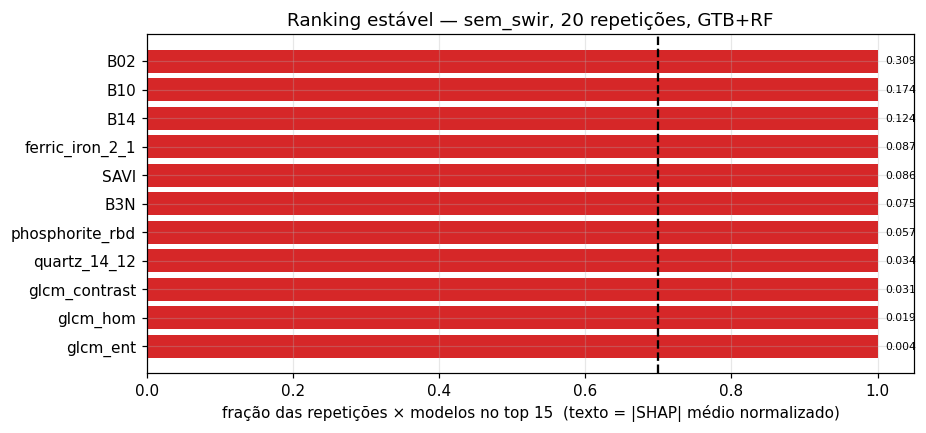

In [17]:
# [14]
import shap

CONJUNTO_SEL = None
if CONJUNTO_SEL is None:
    CONJUNTO_SEL = ABL[ABL.conjunto != 'fixas_v1'].groupby('conjunto').auc_ponto.mean().idxmax()
feats_sel = CONJ[CONJUNTO_SEL]
print(f'conjunto: {CONJUNTO_SEL} ({len(feats_sel)} variáveis)')

def shap_arvore(modelo, X):
    est = modelo.rf if hasattr(modelo, 'rf') else modelo.gb
    sv = shap.TreeExplainer(est).shap_values(X, check_additivity=False)
    if isinstance(sv, list):
        sv = sv[1]
    if sv.ndim == 3:
        sv = sv[..., 1]
    return sv

codigos = PRES.CODIGO_OBJ.unique()
REP = []
for rep in range(N_REP):
    escolhidos = rng.choice(codigos, max(3, int(round(FRAC_REP * len(codigos)))), replace=False)
    p = PRES[PRES.CODIGO_OBJ.isin(escolhidos)]
    for mod in SHAP_MODELOS:
        imp = np.zeros(len(feats_sel))
        for c in sorted(p.celula.unique()):
            p_tr = p[p.celula != c]
            m = MODELOS_CLS[mod]().fit(p_tr[feats_sel].values,
                                       fundo_treino(p_tr, FUNDO[FUNDO.celula != c])[feats_sel].values)
            tp, tf = p[p.celula == c], FUNDO[FUNDO.celula == c]
            X = pd.concat([tp.sample(min(len(tp), SHAP_N // 2), random_state=rep),
                           tf.sample(min(len(tf), SHAP_N // 2), random_state=rep)])[feats_sel].values
            imp += np.abs(shap_arvore(m, X)).mean(0)
        REP.append({'rep': rep, 'modelo': mod, **dict(zip(feats_sel, imp / imp.sum()))})
    print(f'repetição {rep + 1}/{N_REP}')
REP = pd.DataFrame(REP)

imp = REP[feats_sel]
no_topo = imp.rank(axis=1, ascending=False) <= TOP_K
ESTAB = pd.DataFrame({'freq_topo': no_topo.mean(), 'imp_media': imp.mean(),
                      **{f'freq_{m}': no_topo[REP.modelo == m].mean() for m in SHAP_MODELOS}}
                     ).sort_values(['freq_topo', 'imp_media'], ascending=False)
SELECAO = ESTAB.index[ESTAB.freq_topo >= FREQ_MIN].tolist()
n_estaveis = len(SELECAO)
if n_estaveis < N_MIN_SEL:
    SELECAO = ESTAB.index[:min(N_MIN_SEL, len(ESTAB))].tolist()   # ESTAB já em ordem de freq_topo, imp_media
    print(f'{n_estaveis} variáveis com freq_topo ≥ {FREQ_MIN}; completada até {len(SELECAO)} (N_MIN_SEL) '
          f'com as próximas: {SELECAO[n_estaveis:]}')
print(f'SELECAO ({len(SELECAO)}):', SELECAO)

fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(feats_sel))))
e = ESTAB.iloc[::-1]
ax.barh(e.index, e.freq_topo, color=['#d62728' if v in SELECAO else '#bdbdbd' for v in e.index])
ax.axvline(FREQ_MIN, c='k', ls='--')
for i, (v, row) in enumerate(e.iterrows()):
    ax.text(row.freq_topo + 0.01, i, f'{row.imp_media:.3f}', va='center', fontsize=7)
ax.set_xlabel(f'fração das repetições × modelos no top {TOP_K}  (texto = |SHAP| médio normalizado)')
ax.set_title(f'Ranking estável — {CONJUNTO_SEL}, {N_REP} repetições, {"+".join(SHAP_MODELOS)}')
salvar(fig, '14', f'ranking_estavel_{ID_RC}_{CONJUNTO_SEL}_{FUNDO_MODO}')
ESTAB.round(3)

`[14a]`

**Conferência da seleção.** Refaz a validação por célula só com `SELECAO` e compara
com o conjunto de origem. AUC, Boyce e top10 têm que ficar parecidos ou melhores; se
caírem mais que ~0,03, aumente `TOP_K` ou baixe `FREQ_MIN` e rode a [14] de novo.

In [18]:
# [15]
CONJ['selecao'] = SELECAO
for mod, Cls in MODELOS_CLS.items():
    op, of = oof(PRES, FUNDO, SELECAO, Cls)
    OOF[('selecao', mod)] = (op, of)
    ABL = pd.concat([ABL, pd.DataFrame([{'conjunto': 'selecao', 'modelo': mod, 'variaveis': len(SELECAO),
                                         **metricas(op, of, PRES)}])], ignore_index=True)
ABL[ABL.conjunto.isin([CONJUNTO_SEL, 'selecao', 'fixas_v1'])].set_index(['conjunto', 'modelo']).round(3)

variaveis  auc_ponto  auc_p05  auc_p95  ap_ganho  boyce  \
conjunto modelo                                                            
sem_swir RF             11      0.759    0.711    0.806     2.323  0.985   
         GTB            11      0.764    0.712    0.813     3.035  0.934   
fixas_v1 RF             21      0.683    0.625    0.736     1.756  0.774   
         GTB            21      0.682    0.625    0.737     1.701  0.883   
selecao  RF             11      0.761    0.711    0.803     2.439  0.984   
         GTB            11      0.764    0.711    0.815     3.034  0.933   

                 top10  ocorrencias  
conjunto modelo                      
sem_swir RF      0.324           37  
         GTB     0.351           37  
fixas_v1 RF      0.162           37  
         GTB     0.135           37  
selecao  RF      0.324           37  
         GTB     0.351           37

`[16]`

## 6. Avaliação nos pontos

A pergunta que importa para o mapa: **cada ocorrência, vista por um modelo que não
viu a célula dela, cai na parte alta do mapa?** Tudo aqui é sobre os pontos (mediana
do p fora da amostra nos pixels de cada ocorrência), comparado com o fundo fora da
amostra. `CONJUNTO_AVAL` = conjunto avaliado (padrão `selecao`).

**Tabela [17]** — uma linha por ocorrência: célula, papel, p mediano RF e GTB, percentil
no fundo (100 = maior p da região) e se está nos 10% do topo. Gravada em
`models/avaliacao_pontos_RC_<sufixo>_<conjunto>_<modo>.csv`.

**Figura [17].** Percentil de cada ocorrência por célula; linha em 90 = topo de 10% da
área. Uma célula inteira abaixo de 90 = o modelo não transfere para aquela região.

figura → c17_pontos_shm_selecao_cluster.png
        pct_RF  pct_GTB
celula                 
4         80.0     82.0
8         55.0     52.0
10        94.0     97.0
13        82.0     81.0
15        82.0     88.0


,celula,papel,fonte,pixels,p_RF,pct_RF,top10_RF,p_GTB,pct_GTB,top10_GTB
CODIGO_OBJ,,,,,,,,,,
18823,4,treino,antigo+cprm,20,0.281,50.16,False,0.348,55.95,False
18853,4,treino,antigo+cprm,20,0.906,80.44,False,0.983,82.30,False
18824,4,validacao,antigo+cprm,20,0.962,86.48,False,0.991,85.96,False
18826,8,treino,antigo+cprm,20,0.207,46.77,False,0.021,38.54,False
900006,8,treino,cprm,20,0.220,47.47,False,0.047,43.72,False
18828,8,treino,antigo+cprm,20,0.305,51.37,False,0.106,48.16,False
18831,8,treino,antigo+cprm,20,0.269,49.74,False,0.128,49.35,False
18827,8,validacao,antigo+cprm,20,0.397,54.85,False,0.158,50.55,False
18832,8,validacao,antigo+cprm,20,0.317,51.78,False,0.188,51.55,False


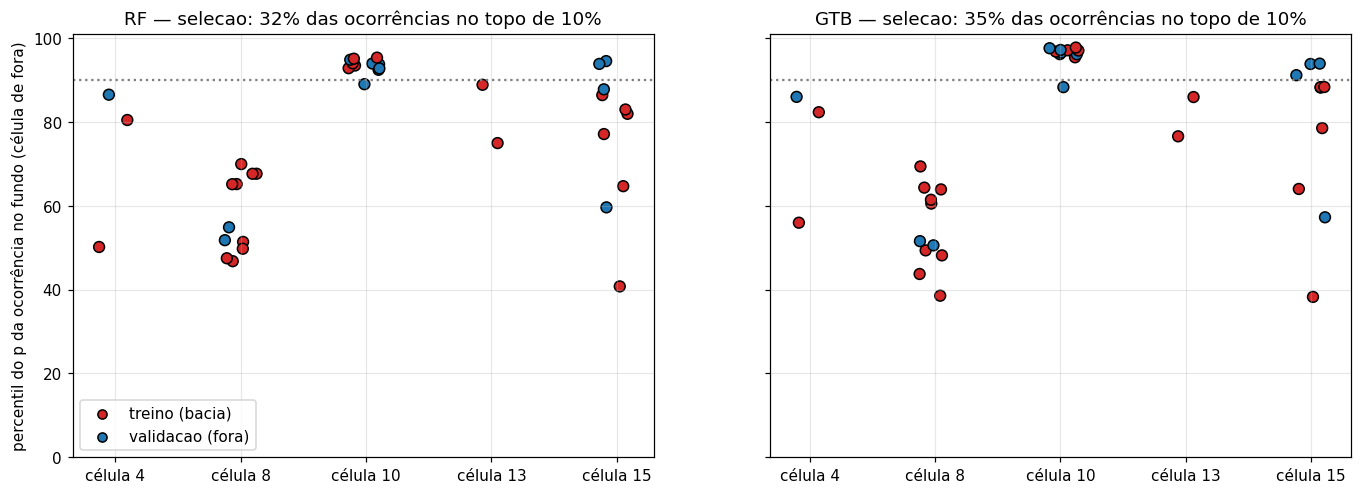

In [19]:
# [17]
CONJUNTO_AVAL = 'selecao'
PONTOS = OC[['celula', 'papel', 'fonte', 'pixels']].copy()
for mod in MODELOS_CLS:
    op, of = OOF[(CONJUNTO_AVAL, mod)]
    pf = np.sort(of.dropna().values)
    med_p = op.groupby(PRES.CODIGO_OBJ).median()
    PONTOS[f'p_{mod}'] = med_p
    PONTOS[f'pct_{mod}'] = np.searchsorted(pf, med_p.loc[PONTOS.index].values) / len(pf) * 100
    PONTOS[f'top10_{mod}'] = PONTOS[f'pct_{mod}'] >= 90
PONTOS = PONTOS.sort_values(['celula', 'pct_GTB'])

fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, mod in zip(axs, MODELOS_CLS):
    for j, (c, g) in enumerate(PONTOS.groupby('celula')):
        x = j + rng.uniform(-0.15, 0.15, len(g))
        ax.scatter(x, g[f'pct_{mod}'], s=50, edgecolor='k',
                   c=np.where(g.papel == 'treino', '#d62728', '#1f77b4'))
    cels = sorted(PONTOS.celula.unique())
    ax.set_xticks(range(len(cels)), [f'célula {c}' for c in cels])
    ax.axhline(90, c='grey', ls=':'); ax.set_ylim(0, 101)
    ax.set_title(f'{mod} — {CONJUNTO_AVAL}: {PONTOS[f"top10_{mod}"].mean():.0%} das ocorrências no topo de 10%')
axs[0].set_ylabel('percentil do p da ocorrência no fundo (célula de fora)')
axs[0].scatter([], [], c='#d62728', edgecolor='k', label='treino (bacia)')
axs[0].scatter([], [], c='#1f77b4', edgecolor='k', label='validacao (fora)')
axs[0].legend(loc='lower left')
salvar(fig, '17', f'pontos_{ID_RC}_{CONJUNTO_AVAL}_{FUNDO_MODO}')
print(PONTOS.groupby('celula')[[f'pct_{m}' for m in MODELOS_CLS]].median().round(0))
PONTOS.to_csv(MODELS / f'avaliacao_pontos_RC_{ID_RC}_{CONJUNTO_AVAL}_{FUNDO_MODO}.csv')
PONTOS.round(3)

`[18]`

**Validação R2 (independente).** Treina só com as ocorrências `papel = treino` (bacia de
Irecê) e testa nas `validacao` (fora da bacia). O fundo das células que têm ocorrência
de validação sai do treino e é o fundo de avaliação: o teste não vê nada da região
testada. Compara os conjuntos `selecao`, `CONJUNTO_SEL` e `fixas_v1`.

Se a AUC por ponto aqui ficar perto da [15], o modelo transfere para fora da bacia;
se cair muito, o mapa reconhece a bacia e não o fosfato (a mesma limitação da área
reduzida). Só vale com `PAPEIS = None` (com `['treino']` não há pontos de validação).

In [21]:
# [19]
pt_all = df[(df.classe == 1) & (df.alvo == ALVO)]
p_tr, p_va = pt_all[pt_all.papel == 'treino'], pt_all[pt_all.papel == 'validacao']
cel_va = sorted(p_va.celula.unique())
f_tr, f_va = FUNDO[~FUNDO.celula.isin(cel_va)], FUNDO[FUNDO.celula.isin(cel_va)]
print(f'treino: {p_tr.CODIGO_OBJ.nunique()} ocorrências em {sorted(p_tr.celula.unique())}; '
      f'validação: {p_va.CODIGO_OBJ.nunique()} em {cel_va}; fundo treino {len(f_tr)}, avaliação {len(f_va)}')
p_tr = p_tr[~p_tr.celula.isin(cel_va)]   # treino na mesma célula da validação também sai
R2 = []
for nome in dict.fromkeys(['selecao', CONJUNTO_SEL, 'fixas_v1']):
    feats = CONJ[nome]
    for mod, Cls in MODELOS_CLS.items():
        m = Cls().fit(p_tr[feats].values, fundo_treino(p_tr, f_tr)[feats].values)
        op = pd.Series(m.predict(p_va[feats].values), index=p_va.index)
        of = pd.Series(m.predict(f_va[feats].values), index=f_va.index)
        R2.append({'conjunto': nome, 'modelo': mod, **metricas(op, of, p_va)})
R2 = pd.DataFrame(R2)
R2.to_csv(MODELS / f'selecao_RC_{ID_RC}_{FUNDO_MODO}_validacao_R2.csv', index=False)
R2.set_index(['conjunto', 'modelo']).round(3)

treino: 24 ocorrências em [np.int64(4), np.int64(8), np.int64(10), np.int64(13), np.int64(15)]; validação: 13 em [np.int64(4), np.int64(8), np.int64(10), np.int64(15)]; fundo treino 8400, avaliação 1600


auc_ponto  auc_p05  auc_p95  ap_ganho  boyce  top10  \
conjunto modelo                                                        
selecao  RF          0.647    0.577    0.713     1.488  0.665  0.077   
         GTB         0.636    0.570    0.702     1.397  0.764  0.077   
sem_swir RF          0.644    0.580    0.718     1.522  0.634  0.077   
         GTB         0.636    0.563    0.706     1.397  0.764  0.077   
fixas_v1 RF          0.593    0.491    0.702     1.331  0.778  0.077   
         GTB         0.584    0.478    0.685     1.299  0.777  0.000   

                 ocorrencias  
conjunto modelo               
selecao  RF               13  
         GTB              13  
sem_swir RF               13  
         GTB              13  
fixas_v1 RF               13  
         GTB              13

`[20]`

## 7. Variáveis salvas para o export

`models/variaveis_RC_<sufixo>.json` leva todos os conjuntos (o
`exportar_favorabilidade_ml.py` oferece todos no menu, mais `fixas`), com `selecao`
como recomendado, o `fundo_modo` e os `papeis`. Com `fundo_modo = 'cluster'`, o
export lê o `cluster_fundo_RC_<sufixo>.json` da [10e] e o nome do asset ganha `_fcl`.
Para mudar o recomendado, troque `RECOMENDADO` antes de rodar.

In [22]:
# [21]
RECOMENDADO = 'selecao'
saida = {
    'mosaico': MOSAICO, 'id': ID_RC, 'alvo': ALVO, 'papeis': PAPEIS,
    'conjuntos': {k: list(v) for k, v in CONJ.items()},
    'recomendado': RECOMENDADO, 'conjunto_base_selecao': CONJUNTO_SEL, 'fundo_modo': FUNDO_MODO,
    'parametros': {'R_MAX': R_MAX, 'N_REP': N_REP, 'FRAC_REP': FRAC_REP, 'TOP_K': TOP_K, 'FREQ_MIN': FREQ_MIN, 'N_MIN_SEL': N_MIN_SEL,
                   'SHAP_MODELOS': SHAP_MODELOS, 'K_FUNDO': K_FUNDO, 'FRAC_MIN_FUNDO': FRAC_MIN_FUNDO,
                   'REGRA_FUNDO': REGRA_FUNDO, 'N_CLUSTERS_FUNDO': N_CLUSTERS_FUNDO,
                   'VARS_CL': list(VARS_CL), 'FATOR_FUNDO': FATOR_FUNDO},
}
arq = MODELS / f'variaveis_RC_{ID_RC}.json'
arq.write_text(json.dumps(saida, indent=1, ensure_ascii=False))
ABL.to_csv(MODELS / f'selecao_RC_{ID_RC}_{FUNDO_MODO}_ablacao.csv', index=False)
ESTAB.to_csv(MODELS / f'selecao_RC_{ID_RC}_{FUNDO_MODO}_ranking_estavel.csv')
print(f'→ {arq}\n  {RECOMENDADO} = {CONJ[RECOMENDADO]}')

→ /home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/variaveis_RC_shm.json
  selecao = ['B02', 'B10', 'B14', 'ferric_iron_2_1', 'SAVI', 'B3N', 'phosphorite_rbd', 'quartz_14_12', 'glcm_contrast', 'glcm_hom', 'glcm_ent']
